# 08 Dose recommendation

Dose optimum from the San + SVR hybrid, limited to doses tested on waters of similar turbidity, then a leave-one-day-out check of dose choice and one-jar calibration.

In [12]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from scipy import stats

from src.config import DATA_PROC, RESULTS, SED_TIMES
from src.features import make_table
from src import hybrid as H
from src import kinetics as kin
from src import style

style.apply()
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 160)

N_TRIALS = 15
HF = ["dose", "log_t0_raw"]
TIMES = SED_TIMES[1:]
SED = 60
TOL = 0.02
P_TARGET = 0.6
T0_LEVELS = [30, 90, 200]
DOSES = np.arange(40, 351, 5.0)
PRED = RESULTS / "predictions"
MET = RESULTS / "metrics"

## 1. Final hybrid (all 22 days)

In [13]:
long = pd.read_csv(DATA_PROC / "long.csv", parse_dates=["date"])
tab = make_table(long, level="cell")
jars = tab.drop_duplicates("run").set_index("run").sort_index()
Yj = tab.pivot(index="run", columns="sed", values="log_ratio").loc[jars.index, TIMES].to_numpy()
fits = pd.read_csv(DATA_PROC / "kinetic_fits.csv")
Z = H.to_targets(fits[fits["model"] == "san"].set_index("run").loc[jars.index, ["tau", "b"]].to_numpy(), "san")
Xj = jars[HF].to_numpy(float)
p = H.tune("svr", "san", Xj, Z, Yj, jars["day"].to_numpy(), TIMES, HF, N_TRIALS)
hyb = H.make_reg("svr", p, HF).fit(Xj, Z)
print(p)


def params(dose, t0):
    d = np.atleast_1d(np.asarray(dose, float))
    return H.from_targets(hyb.predict(np.column_stack([d, np.full(len(d), np.log10(t0))])), "san")


def removal(dose, t0, t=SED):
    P = params(dose, t0)
    return 1 - kin.san(t, 1.0, P[:, 0], P[:, 1])


def time_to(dose, t0, target=P_TARGET):
    P = params(dose, t0)
    return P[:, 0] * (target / (1 - target)) ** (1 / P[:, 1])

{'C': 3.4890188454913864, 'gamma': 0.05987474910461398, 'epsilon': 0.001238513729886093}


## 2. Dose-response and recommended dose

In [14]:
def tested(t0, width=0.15):
    near = jars.loc[np.abs(jars["log_t0_raw"] - np.log10(t0)) <= width, "dose"]
    return DOSES[(DOSES >= near.min()) & (DOSES <= near.max())]


rows = []
for t0 in np.linspace(30, 260, 24):
    d = tested(t0)
    r = removal(d, t0)
    best = d[r.argmax()]
    lean = d[np.argmax(r >= r.max() - TOL)]
    rows.append({"t0_raw": t0, "dose_min_tested": d.min(), "dose_max_tested": d.max(),
                 "best_dose": best, "removal_best": r.max(), "lean_dose": lean,
                 "removal_lean": removal(lean, t0)[0], "t_target_best": time_to(best, t0)[0]})
rec = pd.DataFrame(rows)
rec.iloc[::3].round(3)

,t0_raw,dose_min_tested,dose_max_tested,best_dose,removal_best,lean_dose,removal_lean,t_target_best
0,30.0,40.0,300.0,85.0,0.588,40.0,0.577,61.711
3,60.0,70.0,180.0,85.0,0.740,70.0,0.739,38.884
6,90.0,50.0,350.0,75.0,0.823,50.0,0.821,25.392
9,120.0,50.0,350.0,60.0,0.868,50.0,0.867,18.010
12,150.0,85.0,350.0,85.0,0.889,85.0,0.889,13.487
15,180.0,85.0,350.0,85.0,0.904,85.0,0.904,10.630
18,210.0,65.0,350.0,65.0,0.918,65.0,0.918,8.731
21,240.0,65.0,350.0,65.0,0.925,65.0,0.925,7.375


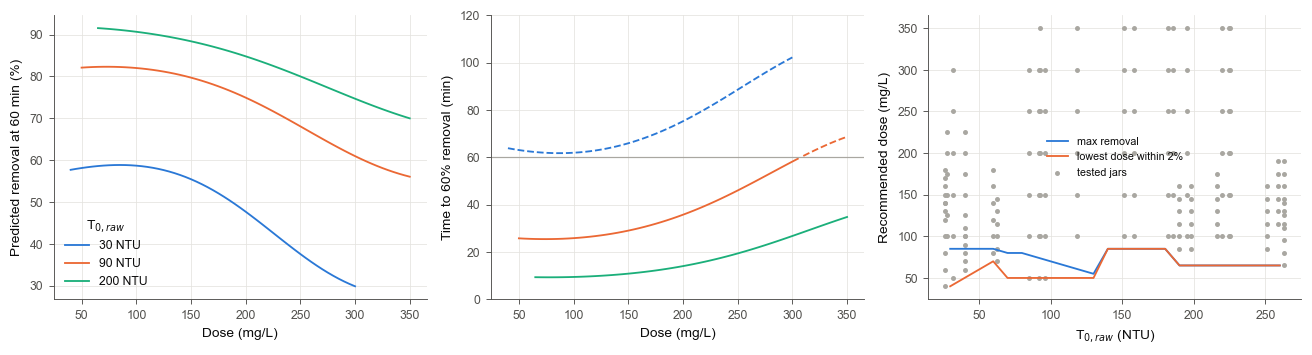

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for i, t0 in enumerate(T0_LEVELS):
    c, d = style.COLORS[i], tested(t0)
    axes[0].plot(d, 100 * removal(d, t0), color=c, label=f"{t0} NTU")
    tt = time_to(d, t0)
    axes[1].plot(d, np.where(tt <= SED, tt, np.nan), color=c)
    axes[1].plot(d, np.where(tt > SED, tt, np.nan), color=c, ls="--")
axes[0].set_ylabel(f"Predicted removal at {SED} min (%)")
axes[0].legend(title="T$_{0,raw}$")
axes[1].set_ylim(0, 120)
axes[1].axhline(SED, color=style.MUTED, lw=0.8)
axes[1].set_ylabel(f"Time to {P_TARGET:.0%} removal (min)")
for ax in axes[:2]:
    ax.set_xlabel("Dose (mg/L)")
axes[2].plot(rec["t0_raw"], rec["best_dose"], color=style.COLORS[0], label="max removal")
axes[2].plot(rec["t0_raw"], rec["lean_dose"], color=style.COLORS[1], label=f"lowest dose within {TOL:.0%}")
axes[2].scatter(jars["t0_raw"], jars["dose"], s=5, color=style.MUTED, label="tested jars")
axes[2].set_xlabel("T$_{0,raw}$ (NTU)")
axes[2].set_ylabel("Recommended dose (mg/L)")
axes[2].legend(fontsize=7)
fig.tight_layout()
style.save(fig, "fig01_dose_recommendation", "dose")
plt.show()

Dashed lines: times beyond the 60 min measured.

## 3. Leave-one-day-out check of dose choice

Shortfall: best observed removal at 60 min that day minus removal at the chosen dose (percentage points).

In [16]:
dose_of = jars["dose"]
obs = (tab[tab["sed"] == SED].assign(rem=lambda d: 1 - d["turb"] / d["t0_raw"])
       .groupby(["day", "dose"])["rem"].mean())


def predicted(path):
    g = pd.read_csv(path)
    g = g[g["sed"] == SED].assign(dose=lambda d: d["run"].map(dose_of), rem=lambda d: 1 - 10 ** d["pred"] / d["t0_raw"])
    return g.groupby(["day", "dose"])["rem"].mean()


sources = {"hybrid San + SVR": PRED / "05" / "hyb_san_svr__core__lodo.csv",
           "SVR": PRED / "03" / "svr__core__lodo.csv",
           "MLP": PRED / "03" / "mlp__core__lodo.csv",
           "TabPFN": PRED / "04" / "tabpfn__core__lodo.csv"}
pred = {k: predicted(v) for k, v in sources.items()}
best_dose = obs.groupby("day").idxmax().str[1]

rows = []
for d, o in obs.groupby("day"):
    o = o.droplevel("day")
    pick = {k: v.loc[d].idxmax() for k, v in pred.items()}
    h = pred["hybrid San + SVR"].loc[d]
    pick["hybrid, lowest within 2 pp"] = h.index[np.argmax(h.values >= h.max() - TOL)]
    fixed = best_dose.drop(d).median()
    pick["fixed (median best dose of other days)"] = o.index[np.abs(o.index - fixed).argmin()]
    for k, dose in pick.items():
        rows.append({"day": d, "strategy": k, "dose": dose, "regret_pp": 100 * (o.max() - o[dose]),
                     "dose_minus_best": dose - o.idxmax()})
    rows.append({"day": d, "strategy": "random tested dose", "dose": o.index.to_numpy().mean(),
                 "regret_pp": 100 * (o.max() - o).mean(), "dose_minus_best": (o.index - o.idxmax()).to_numpy().mean()})
choice = pd.DataFrame(rows)
summary = choice.groupby("strategy").agg(
    mean_regret_pp=("regret_pp", "mean"), median_regret_pp=("regret_pp", "median"),
    share_within_2pp=("regret_pp", lambda r: (r <= 100 * TOL).mean()),
    mean_dose=("dose", "mean"), mean_dose_minus_best=("dose_minus_best", "mean")).sort_values("mean_regret_pp")
w = choice.pivot(index="day", columns="strategy", values="regret_pp")
for k in ["fixed (median best dose of other days)", "random tested dose"]:
    print(f"hybrid vs {k}: Wilcoxon p = {stats.wilcoxon(w['hybrid San + SVR'], w[k]).pvalue:.3f}")
summary.round(3)

hybrid vs fixed (median best dose of other days): Wilcoxon p = 0.010
hybrid vs random tested dose: Wilcoxon p = 0.002


,mean_regret_pp,median_regret_pp,share_within_2pp,mean_dose,mean_dose_minus_best
strategy,,,,,
fixed (median best dose of other days),1.086,0.186,0.773,100.455,-23.409
TabPFN,2.168,0.944,0.545,97.727,-26.136
"hybrid, lowest within 2 pp",2.259,0.760,0.591,82.500,-41.364
SVR,2.281,0.760,0.591,81.136,-42.727
MLP,2.437,0.914,0.545,86.136,-37.727
hybrid San + SVR,2.845,0.914,0.591,92.727,-31.136
random tested dose,8.407,4.933,0.182,168.492,44.628


## 4. One-jar calibration on a new day

One jar from the new day is measured and its mean log residual shifts the predictions for the other jars of that day. Two versions: the jar's full curve, or only its 10 min reading. Every jar takes a turn as the calibration jar.

In [17]:
g = pd.read_csv(sources["hybrid San + SVR"]).assign(res=lambda d: d["log_turb"] - d["pred"])
rmse = lambda r: np.sqrt(np.mean(r ** 2))
rows = []
for d, gd in g.groupby("day"):
    for r in gd["run"].unique():
        cal, rest = gd[gd["run"] == r], gd[gd["run"] != r]
        rows.append({"day": d, "none": rmse(rest["res"]),
                     "one jar, all times": rmse(rest["res"] - cal["res"].mean()),
                     "one jar, 10 min only": rmse(rest["res"] - cal.loc[cal["sed"] == 10, "res"].mean())})
cal = pd.DataFrame(rows).groupby("day").mean()
for k in cal.columns[1:]:
    print(f"{k}: Wilcoxon vs none p = {stats.wilcoxon(cal['none'], cal[k]).pvalue:.2e}")
cal_tab = pd.DataFrame({"mean_day_rmse": cal.mean(), "days_improved": (cal.lt(cal["none"], axis=0)).sum()})
cal_tab.round(4)

one jar, all times: Wilcoxon vs none p = 3.88e-01
one jar, 10 min only: Wilcoxon vs none p = 5.24e-01


,mean_day_rmse,days_improved
none,0.1373,0
"one jar, all times",0.1153,12
"one jar, 10 min only",0.1236,13


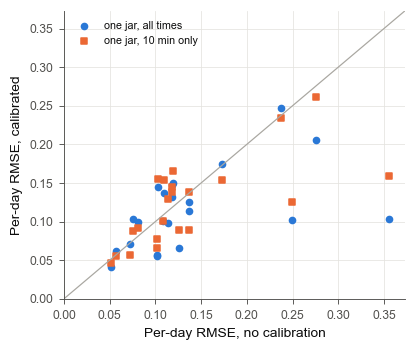

In [18]:
fig, ax = plt.subplots(figsize=(4, 3.4))
for i, k in enumerate(cal.columns[1:]):
    ax.scatter(cal["none"], cal[k], color=style.COLORS[i], marker=style.MARKERS[i], label=k)
lim = [0, cal.to_numpy().max() * 1.05]
ax.plot(lim, lim, color=style.MUTED, lw=0.8)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("Per-day RMSE, no calibration")
ax.set_ylabel("Per-day RMSE, calibrated")
ax.legend(fontsize=7)
style.save(fig, "fig02_one_jar_calibration", "dose")
plt.show()

## 5. Save

In [19]:
rec.round(4).to_csv(MET / "08_recommended_dose.csv", index=False)
choice.round(4).to_csv(MET / "08_dose_choice_by_day.csv", index=False)
summary.round(4).to_csv(MET / "08_dose_choice_summary.csv")
cal.round(5).to_csv(MET / "08_calibration_by_day.csv")
key = {"hybrid_params": p,
       "mean_regret_pp": summary["mean_regret_pp"].round(2).to_dict(),
       "calibration_mean_day_rmse": cal_tab["mean_day_rmse"].round(4).to_dict()}
(MET / "08_key_numbers.json").write_text(json.dumps(key, indent=2))
key

{'hybrid_params': {'C': 3.4890188454913864,
  'gamma': 0.05987474910461398,
  'epsilon': 0.001238513729886093},
 'mean_regret_pp': {'fixed (median best dose of other days)': 1.09,
  'TabPFN': 2.17,
  'hybrid, lowest within 2 pp': 2.26,
  'SVR': 2.28,
  'MLP': 2.44,
  'hybrid San + SVR': 2.85,
  'random tested dose': 8.41},
 'calibration_mean_day_rmse': {'none': 0.1373,
  'one jar, all times': 0.1153,
  'one jar, 10 min only': 0.1236}}